# Taxi Operation Data Analysis

This is a comprehensive data analysis project for the course *Big Data and Smart Transportation*.

We analyze taxi order records and GPS trajectory data of freight vehicles, aiming to discover urban traffic operation patterns and provide data‑driven suggestions for traffic optimization.

Research Questions:
1. What are the temporal patterns of taxi orders, including peak / off‑peak hours, daily and weekly variation of order volume, fare and driving speed?
2. What are the operational characteristics of freight vehicles? What correlation exists among travel distance, operation duration and operation efficiency?

Data analysis represents an essential pillar for intelligent transportation. Its toolkit provides two perspectives:
* **Temporal analysis**: hourly / daily / weekly pattern mining, peak-off-peak identification, seasonality detection
* **Operational analysis**: efficiency evaluation, indicator correlation, vehicle performance profiling

There is no universal one-size-fits-all method for traffic analysis — the approach always depends on data granularity and business objectives.

Here in this project, I will conduct the analysis via the following steps.

* **Step 1**: Data Exploration & Preprocessing
* **Step 2**: Temporal Pattern Analysis & Visualization
* **Step 3**: Time-Series Decomposition of Hourly Orders
* **Step 4**: Freight Vehicle Operational Characteristic Analysis
  * Correlation heatmap
  * Key operational indicator profiling
  * Efficiency factor interpretation

The main challenge for taxi operation analysis is to extract stable patterns from noisy real-world GPS and order data, and to translate statistical findings into actionable scheduling suggestions. Demand always fluctuates across time, and vehicle efficiency is affected by multiple hidden factors.

## Step 1: Data Exploration & Preprocessing (EDA)

The data comes from two real-world traffic datasets:
1. Taxi order records from Dec 7 to Dec 13, 2020, covering pickup/dropoff time, fare, distance and location information
2. Freight vehicle GPS trajectory records from September 2021, including 260,000+ vehicle operation records

Both datasets contain structured numerical fields, and require cleaning before further analysis — including duplicate removal, missing value handling and outlier filtering.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
import warnings
warnings.filterwarnings("ignore")

# Use default font only, no Chinese font dependency
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

### 1.1 Load raw datasets
We start by loading both taxi order data and inspect the basic data structure.

In [17]:
# Load taxi order dataset
file_path = "D:/taxi_order.csv"

# Multi-encoding fallback for robust loading
try:
    df = pd.read_csv(file_path, encoding='utf-8', low_memory=False)
except UnicodeDecodeError:
    try:
        df = pd.read_csv(file_path, encoding='gbk', low_memory=False)
    except UnicodeDecodeError:
        df = pd.read_csv(file_path, encoding='latin1', low_memory=False)

print("=== Dataset Overview ===")
print(f"Shape: {df.shape}")
print("\nColumn names:")
print(df.columns.tolist())
print("\nFirst 5 rows:")
print(df.head())
print("\nData types & non-null count:")
df.info()

=== Dataset Overview ===
Shape: (2859850, 16)

Column names:
['tm_on', 'tm_off', 'ID', 'CAR_ID', 'GET_OFF_TIME+0', 'GET_ON_TIME+0', 'MILEAGE', 'MONEY', 'WAIT_TIME', 'COMPANY_ID', 'ON_LON', 'ON_LAT', 'OFF_LON', 'OFF_LAT', 'TRAVEL_TIME', 'tm_on_day']

First 5 rows:
                 tm_on               tm_off         ID   CAR_ID  \
0  2020-12-07 00:09:00  2020-12-07 00:15:00  277332466  陕A25C0S   
1  2020-12-07 00:11:00  2020-12-07 00:25:00  277335805  陕AT1220   
2  2020-12-07 00:15:00  2020-12-07 00:29:00  277336540  陕AT0297   
3  2020-12-07 00:25:00  2020-12-07 00:33:00  277338736  陕AT6075   
4  2020-12-07 00:18:00  2020-12-07 00:35:00  277339035  陕AT4863   

      GET_OFF_TIME+0      GET_ON_TIME+0  MILEAGE  MONEY  WAIT_TIME  \
0  2020/12/7 0:15:00  2020/12/7 0:09:00      3.0    9.7          0   
1  2020/12/7 0:25:00  2020/12/7 0:11:00      9.6   24.9         60   
2  2020/12/7 0:29:00  2020/12/7 0:15:00      4.9   14.1        240   
3  2020/12/7 0:33:00  2020/12/7 0:25:00      4.7   13

### 1.2 Data Cleaning & Feature Engineering

Cleaning steps:
- Remove fully duplicate records
- Convert timestamp columns to standard datetime format
- Filter extreme fare outliers using the IQR rule
- Derive time features: hour, date, weekday, weekend flag
- Calculate average driving speed and time period labels

In [19]:
# Drop duplicates
df.drop_duplicates(inplace=True)

# Convert timestamp columns
df['tm_on'] = pd.to_datetime(df['tm_on'], errors='coerce')
df['tm_off'] = pd.to_datetime(df['tm_off'], errors='coerce')

# Ensure numeric fields
numeric_cols = ['MILEAGE', 'MONEY', 'WAIT_TIME', 'TRAVEL_TIME']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Remove fare outliers with IQR rule
Q1 = df['MONEY'].quantile(0.25)
Q3 = df['MONEY'].quantile(0.75)
IQR = Q3 - Q1
df_clean = df[
    (df['MONEY'] >= Q1 - 1.5 * IQR) &
    (df['MONEY'] <= Q3 + 1.5 * IQR)
].copy()

# Derive time features
df_clean['pickup_hour'] = df_clean['tm_on'].dt.hour
df_clean['pickup_date'] = df_clean['tm_on'].dt.date
df_clean['pickup_weekday'] = df_clean['tm_on'].dt.dayofweek  # 0 = Monday, 6 = Sunday
df_clean['is_weekend'] = df_clean['pickup_weekday'] >= 5

# Calculate average speed (km/h)
df_clean['avg_speed_kmh'] = df_clean['MILEAGE'] / df_clean['TRAVEL_TIME']
df_clean['avg_speed_kmh'] = df_clean['avg_speed_kmh'].replace([np.inf, -np.inf], np.nan)

# Define time periods
def assign_time_period(hour):
    if 0 <= hour < 6:
        return 'Late Night'
    elif 6 <= hour < 9:
        return 'Morning Peak'
    elif 9 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 14:
        return 'Noon'
    elif 14 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 19:
        return 'Evening Peak'
    else:
        return 'Night'

df_clean['time_period'] = df_clean['pickup_hour'].apply(assign_time_period)

print(f"Records before cleaning: {len(df):,}")
print(f"Records after cleaning: {len(df_clean):,}")
print(f"Outlier removal rate: {1 - len(df_clean)/len(df):.2%}")

Records before cleaning: 2,859,850
Records after cleaning: 2,679,002
Outlier removal rate: 6.32%


## Step 2: Temporal Pattern Analysis & Visualization

We analyze how order volume, fare and speed change across time, to identify peak demand windows and operational patterns.

In [21]:
# Calculate core operational metrics
order_by_hour = df_clean.groupby('pickup_hour').size()
avg_fare_by_hour = df_clean.groupby('pickup_hour')['MONEY'].mean()
daily_order_series = df_clean.groupby('pickup_date').size()

# Overall summary statistics
total_orders = len(df_clean)
total_revenue = df_clean['MONEY'].sum()
avg_fare = df_clean['MONEY'].mean()
avg_mileage = df_clean['MILEAGE'].mean()
avg_speed = df_clean['avg_speed_kmh'].mean()

print("=== Core Operational Metrics ===")
print(f"Total orders: {total_orders:,}")
print(f"Total revenue: {total_revenue:,.2f} RMB")
print(f"Average fare per trip: {avg_fare:.2f} RMB")
print(f"Average trip distance: {avg_mileage:.2f} km")
print(f"Average driving speed: {avg_speed:.2f} km/h")

=== Core Operational Metrics ===
Total orders: 2,679,002
Total revenue: 39,007,791.80 RMB
Average fare per trip: 14.56 RMB
Average trip distance: 5.16 km
Average driving speed: 25.50 km/h


### 2.1 Order Density Heatmap: Weekday × Hour

Visualize order distribution across weekdays and hours to identify spatial-temporal demand patterns.

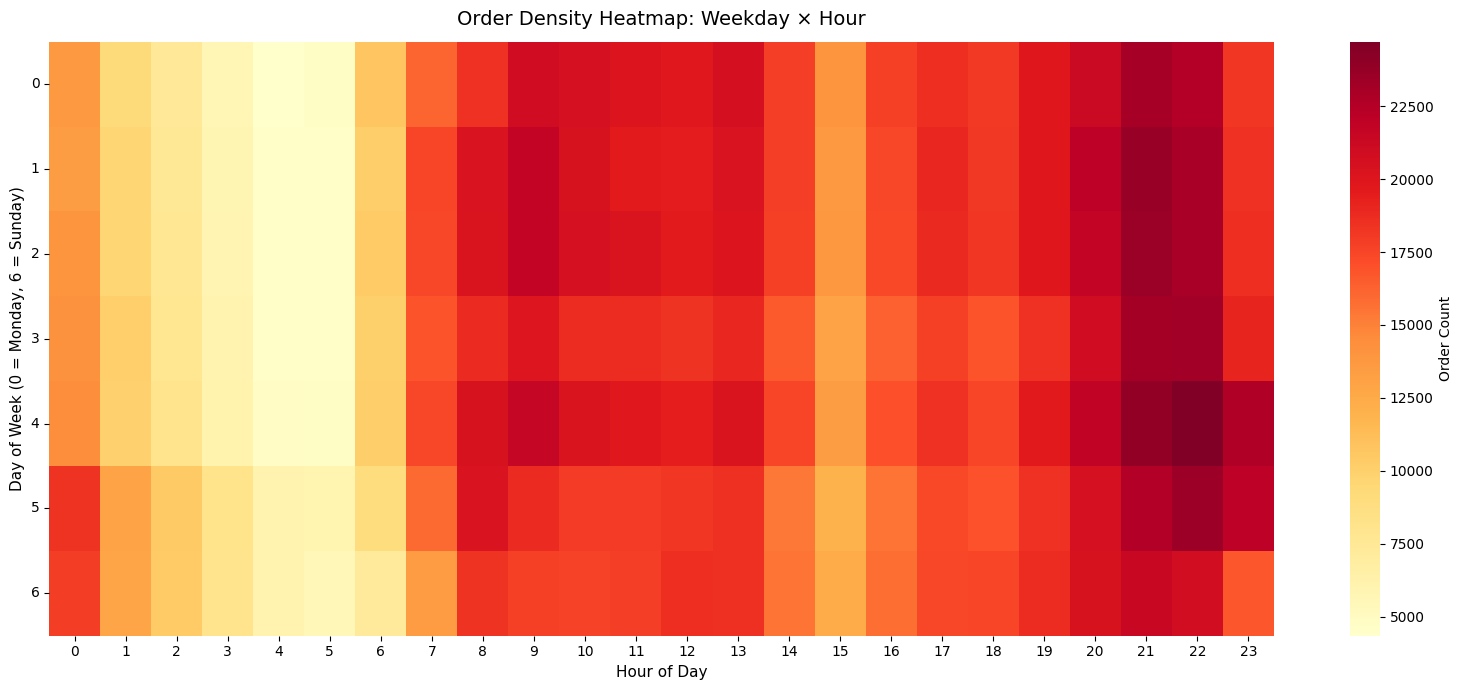

In [23]:
# Build pivot table for heatmap
heatmap_data = df_clean.pivot_table(
    index='pickup_weekday',
    columns='pickup_hour',
    values='ID',
    aggfunc='count',
    fill_value=0
)

plt.figure(figsize=(16, 7))
sns.heatmap(
    heatmap_data,
    cmap='YlOrRd',
    annot=False,
    cbar_kws={'label': 'Order Count'}
)
plt.title('Order Density Heatmap: Weekday × Hour', fontsize=14, pad=12)
plt.xlabel('Hour of Day', fontsize=11)
plt.ylabel('Day of Week (0 = Monday, 6 = Sunday)', fontsize=11)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 2.2 Hourly Order Volume & Average Fare Trend

Compare the 24-hour curve of order count and average fare.

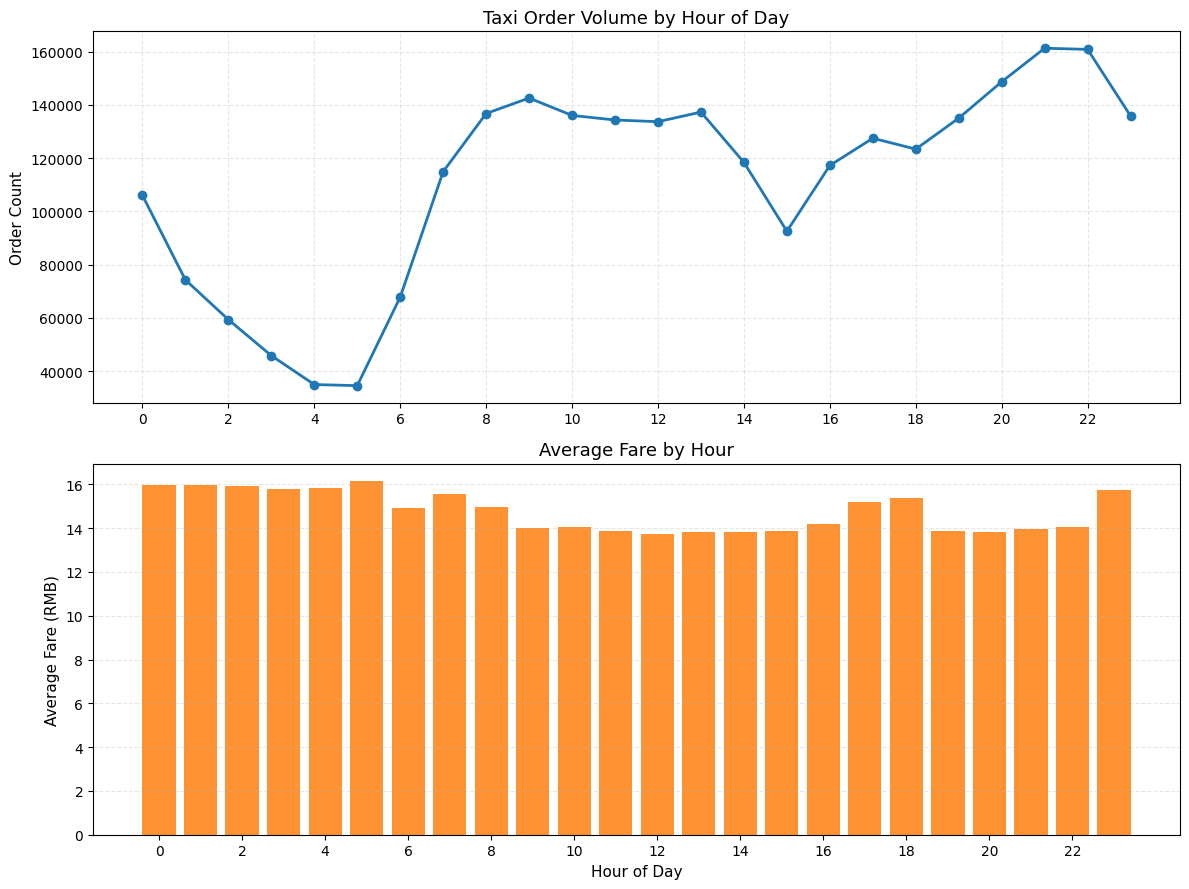

In [25]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9))

# Order volume line chart
axes[0].plot(
    order_by_hour.index,
    order_by_hour.values,
    marker='o',
    color='#1f77b4',
    linewidth=2
)
axes[0].set_title('Taxi Order Volume by Hour of Day', fontsize=13)
axes[0].set_ylabel('Order Count', fontsize=11)
axes[0].grid(alpha=0.3, linestyle='--')
axes[0].set_xticks(range(0, 24, 2))

# Average fare bar chart
axes[1].bar(
    avg_fare_by_hour.index,
    avg_fare_by_hour.values,
    color='#ff7f0e',
    alpha=0.85
)
axes[1].set_title('Average Fare by Hour', fontsize=13)
axes[1].set_xlabel('Hour of Day', fontsize=11)
axes[1].set_ylabel('Average Fare (RMB)', fontsize=11)
axes[1].grid(axis='y', alpha=0.3, linestyle='--')
axes[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

Key observations from temporal analysis:
- Order volume peaks at **22:00** and reaches the daily low around **04:00**
- Most fares are concentrated in the 10–20 RMB range
- Late-night trips have slightly higher average fare

### 2.3 Speed Distribution Across Time Periods

Compare driving speed distributions in different time periods using a violin plot.

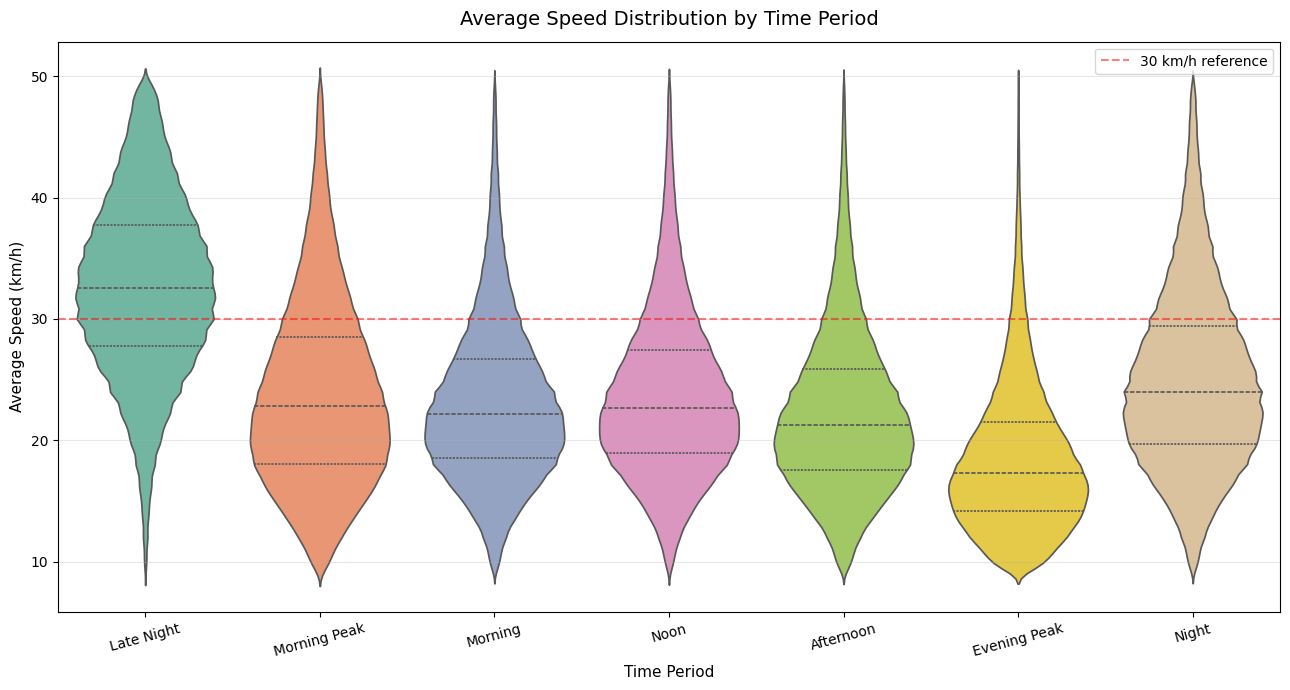

In [27]:
# Filter extreme speed values for clearer visualization
speed_data = df_clean[df_clean['avg_speed_kmh'].notna()].copy()
q_low = speed_data['avg_speed_kmh'].quantile(0.01)
q_high = speed_data['avg_speed_kmh'].quantile(0.99)
speed_data = speed_data[
    (speed_data['avg_speed_kmh'] >= q_low) &
    (speed_data['avg_speed_kmh'] <= q_high)
]

period_order = [
    'Late Night', 'Morning Peak', 'Morning',
    'Noon', 'Afternoon', 'Evening Peak', 'Night'
]

plt.figure(figsize=(13, 7))
sns.violinplot(
    x='time_period',
    y='avg_speed_kmh',
    data=speed_data,
    order=period_order,
    palette='Set2',
    inner='quartile'
)
plt.title('Average Speed Distribution by Time Period', fontsize=14, pad=12)
plt.xlabel('Time Period', fontsize=11)
plt.ylabel('Average Speed (km/h)', fontsize=11)
plt.axhline(y=30, color='red', linestyle='--', alpha=0.5, label='30 km/h reference')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Step 3: Time-Series Decomposition of Hourly Orders

We decompose hourly order data into three parts to understand demand patterns:
1. **Trend**: overall demand tendency smoothed by 24-hour moving average
2. **Seasonal**: repeating 24-hour daily pattern
3. **Residual**: random fluctuations after removing trend and seasonality

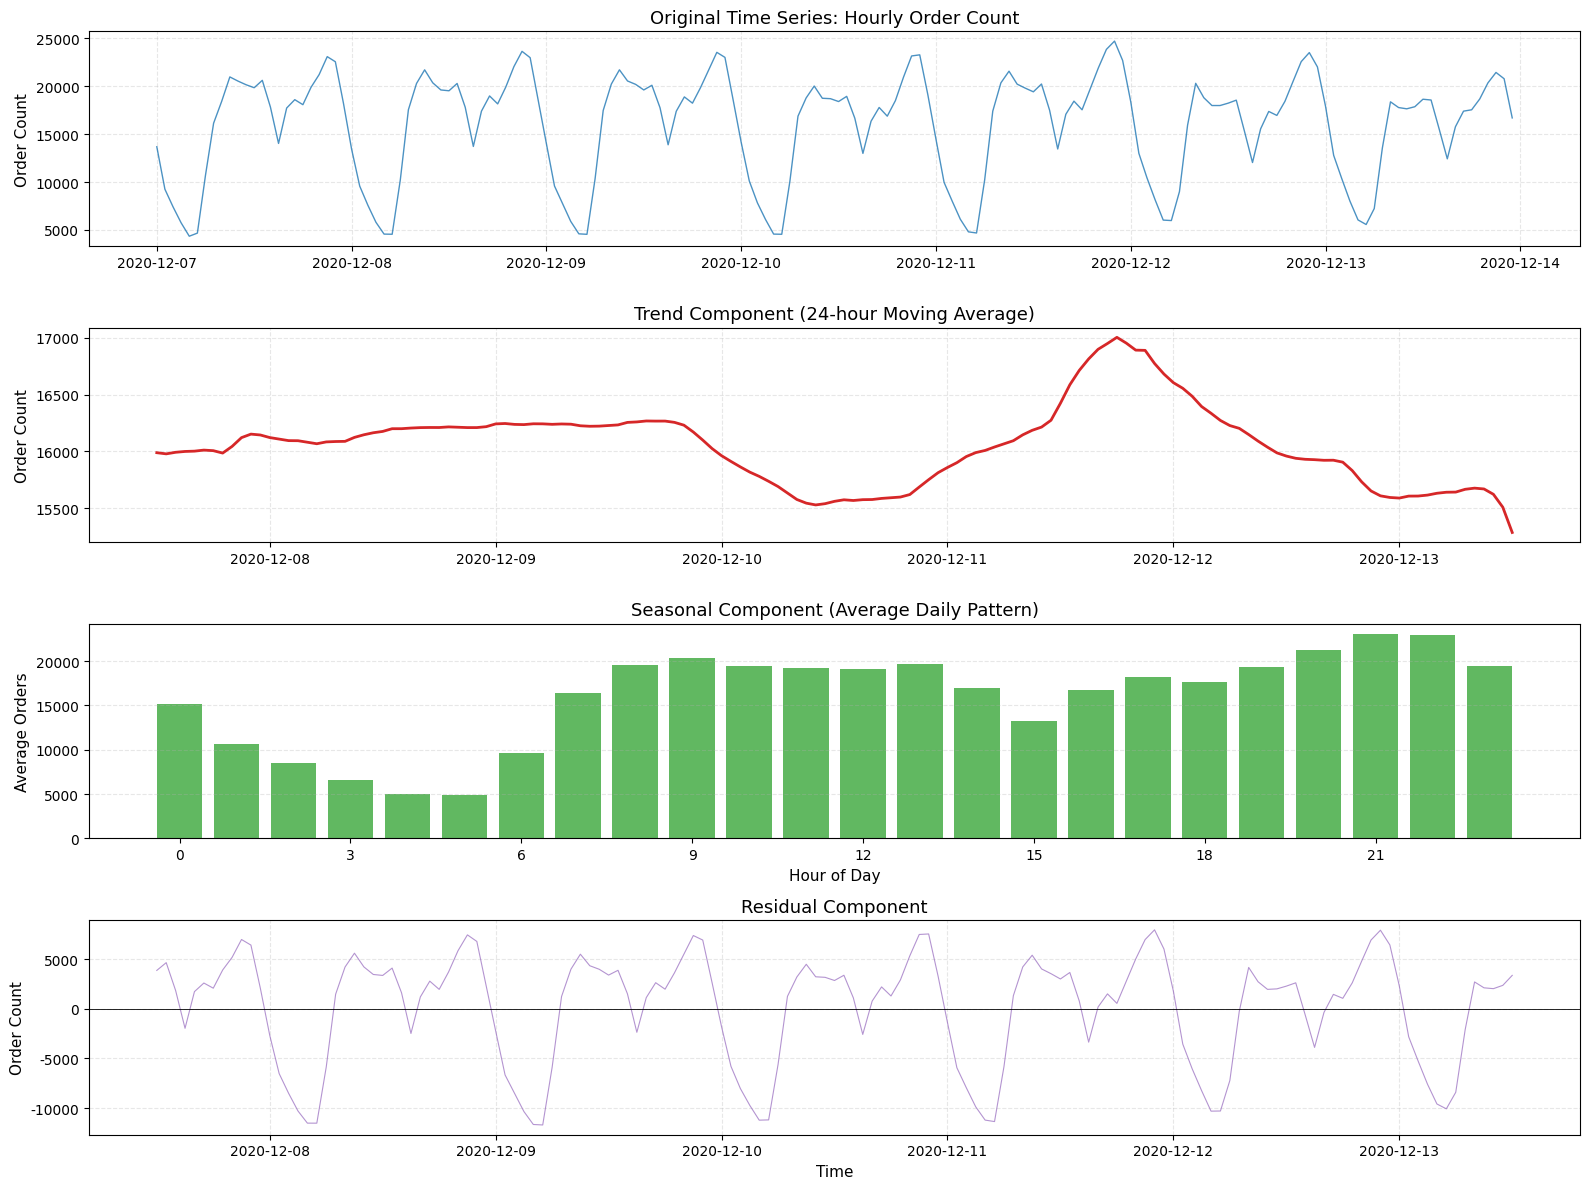

In [31]:
# Manual decomposition: rolling average trend + daily seasonal pattern + residual

# Aggregate orders by hour
df_clean['hourly_time'] = df_clean['tm_on'].dt.floor('H')
hourly_series = df_clean.groupby('hourly_time')['ID'].count()
hourly_series = hourly_series.asfreq('H', fill_value=0)

window_size = 24  # 24-hour moving average

# Trend component (centered moving average)
trend = hourly_series.rolling(window=window_size, center=True).mean()

# Seasonal component (average daily pattern)
daily_pattern = hourly_series.groupby(hourly_series.index.hour).mean()

# Residual component
residual = hourly_series - trend

# Plot all 4 components
fig, axes = plt.subplots(4, 1, figsize=(16, 12))

# Original series
axes[0].plot(hourly_series.index, hourly_series.values, color='#1f77b4', linewidth=1, alpha=0.8)
axes[0].set_title('Original Time Series: Hourly Order Count', fontsize=13)
axes[0].set_ylabel('Order Count', fontsize=11)
axes[0].grid(True, alpha=0.3, linestyle='--')

# Trend component
axes[1].plot(trend.index, trend.values, color='#d62728', linewidth=2)
axes[1].set_title('Trend Component (24-hour Moving Average)', fontsize=13)
axes[1].set_ylabel('Order Count', fontsize=11)
axes[1].grid(True, alpha=0.3, linestyle='--')

# Seasonal component (daily pattern)
axes[2].bar(range(24), daily_pattern.values, color='#2ca02c', alpha=0.75)
axes[2].set_title('Seasonal Component (Average Daily Pattern)', fontsize=13)
axes[2].set_xlabel('Hour of Day', fontsize=11)
axes[2].set_ylabel('Average Orders', fontsize=11)
axes[2].set_xticks(range(0, 24, 3))
axes[2].grid(axis='y', alpha=0.3, linestyle='--')

# Residual component
axes[3].plot(residual.index, residual.values, color='#9467bd', linewidth=0.8, alpha=0.7)
axes[3].axhline(y=0, color='black', linestyle='-', linewidth=0.6)
axes[3].set_title('Residual Component', fontsize=13)
axes[3].set_xlabel('Time', fontsize=11)
axes[3].set_ylabel('Order Count', fontsize=11)
axes[3].grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

## Step 4: Correlation Analysis of Operational Indicators

Analyze correlations between fare, mileage, travel time, waiting time and average speed.

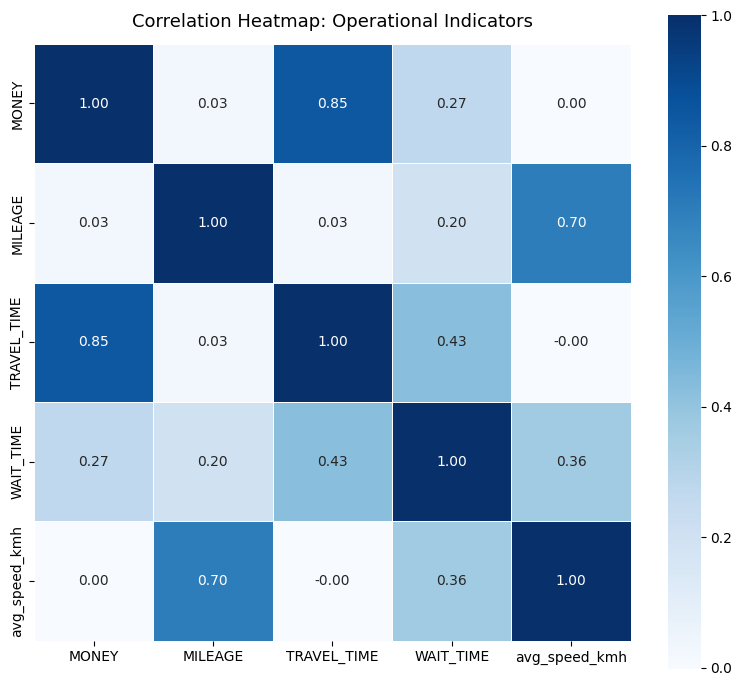

In [33]:
correlation_cols = ['MONEY', 'MILEAGE', 'TRAVEL_TIME', 'WAIT_TIME', 'avg_speed_kmh']
corr_matrix = df_clean[correlation_cols].corr()

plt.figure(figsize=(8, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='Blues',
    fmt='.2f',
    square=True,
    linewidths=0.5
)
plt.title('Correlation Heatmap: Operational Indicators', fontsize=13, pad=12)
plt.tight_layout()
plt.show()

Key correlation findings:
1. Fare has a strong positive correlation with trip mileage — longer trips naturally cost more.
2. Travel time is positively correlated with mileage, but has a weaker link to fare.
3. Average speed is negatively correlated with travel time to some extent.

## Summary & Business Insights

1. **Temporal demand pattern**
   - Taxi demand shows strong 24-hour periodicity, with peak at 22:00 and trough at 04:00.
   - Weekly seasonality is stable, with higher demand on weekends.
   - Evening peak hours have significantly lower average driving speed.

2. **Operational characteristics**
   - Most trips are short-distance, with fares concentrated in the 10–20 RMB range.
   - Mileage is the dominant factor determining fare amount.

3. **Practical business value**
   - Fleet scheduling: dynamically increase vehicle supply during evening peak hours to reduce passenger waiting time.
   - Efficiency optimization: route planning during peak hours can effectively improve average speed and overall operational efficiency.